In [13]:
# Données

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PATH = "Fraudulent_E-Commerce_Transaction_Data.csv"
df = pd.read_csv(PATH)

# noms en snake_case
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe(include="all").T)

(1472952, 16)
transaction_id                   str
customer_id                      str
transaction_amount           float64
transaction_date      datetime64[us]
payment_method                   str
product_category                 str
quantity                       int64
customer_age                   int64
customer_location                str
device_used                      str
ip_address                       str
shipping_address                 str
billing_address                  str
is_fraudulent                  int64
account_age_days               int64
transaction_hour               int64
dtype: object
transaction_id        0
customer_id           0
transaction_amount    0
transaction_date      0
payment_method        0
product_category      0
quantity              0
customer_age          0
customer_location     0
device_used           0
ip_address            0
shipping_address      0
billing_address       0
is_fraudulent         0
account_age_days      0
transaction_hour    

In [14]:
# vérifications critiques

target = "is_fraudulent"
print("Taux de fraude :", df[target].mean())
print("Période :", df.transaction_date.min(), "->", df.transaction_date.max())
print("Doublons transaction_id :", df.transaction_id.duplicated().sum())

# Décide du sort des variables comportementales
n_cust = df.customer_id.nunique()
tx_per_cust = df.groupby("customer_id").size()
print(f"Clients uniques : {n_cust} / {len(df)} lignes")
print(tx_per_cust.describe())
print("Part de clients avec >=2 transactions :", (tx_per_cust >= 2).mean())

# Anomalies de valeurs
print(df.customer_age.describe())
print((df.customer_age <= 0).sum(), "âges <= 0 ;", (df.transaction_amount <= 0).sum(), "montants <= 0")

# L'heure fournie est-elle cohérente avec la date ?
print("Cohérence heure :", (df.transaction_date.dt.hour == df.transaction_hour).mean())

Taux de fraude : 0.05012926422585393
Période : 2024-01-01 00:00:00 -> 2024-04-03 08:13:56
Doublons transaction_id : 0
Clients uniques : 1472952 / 1472952 lignes
count    1472952.0
mean           1.0
std            0.0
min            1.0
25%            1.0
50%            1.0
75%            1.0
max            1.0
dtype: float64
Part de clients avec >=2 transactions : 0.0
count    1.472952e+06
mean     3.451208e+01
std      1.000313e+01
min     -1.600000e+01
25%      2.800000e+01
50%      3.500000e+01
75%      4.100000e+01
max      8.600000e+01
Name: customer_age, dtype: float64
521 âges <= 0 ; 0 montants <= 0
Cohérence heure : 0.9806646788218489


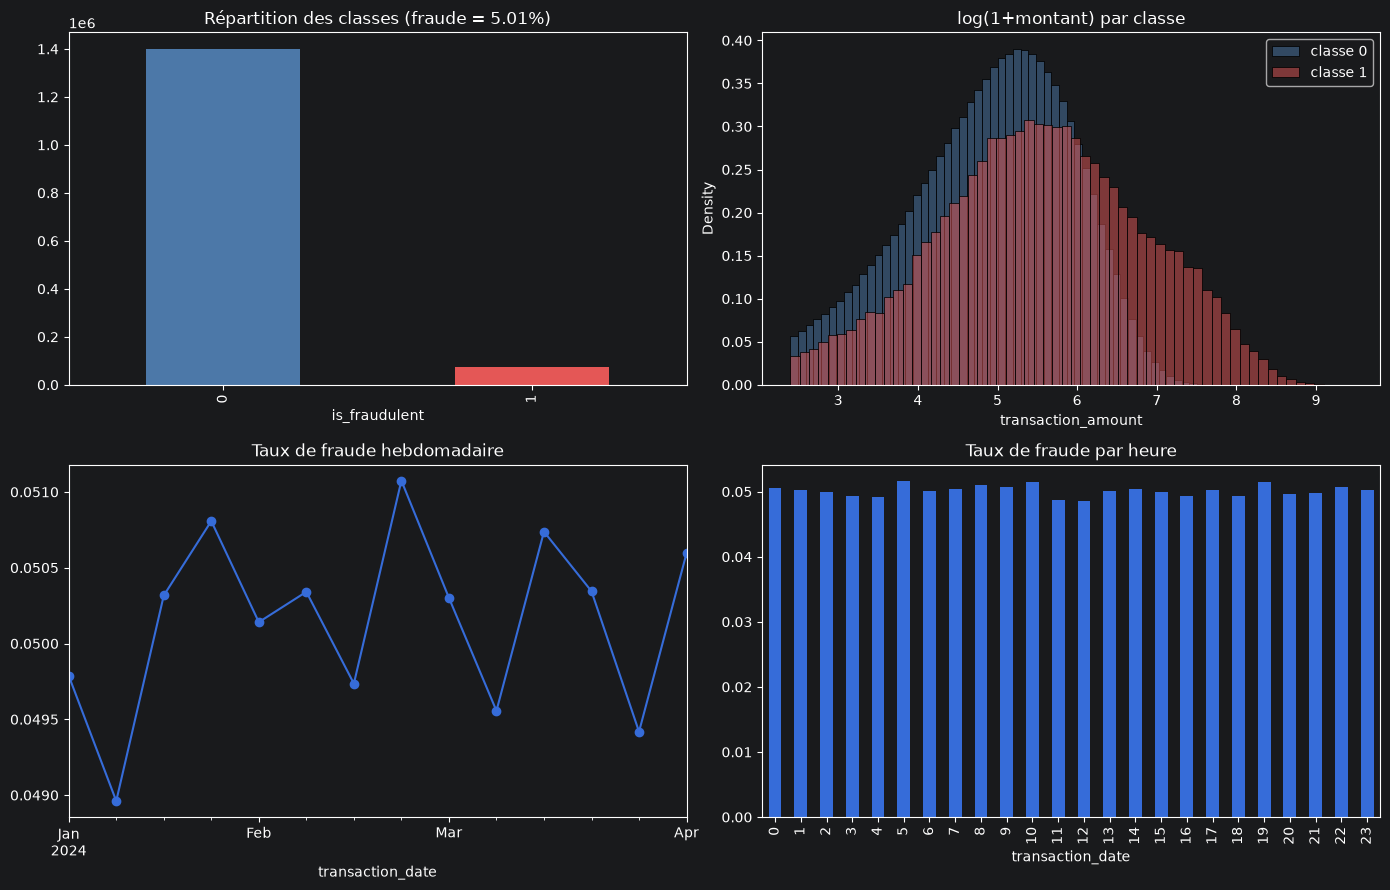

In [15]:
# visualisations exploratoires

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Taux de fraude + déséquilibre
df[target].value_counts().plot.bar(ax=axes[0,0], color=["#4C78A8", "#E45756"])
axes[0,0].set_title(f"Répartition des classes (fraude = {df[target].mean():.2%})")

# 2) Distribution des montants par classe (échelle log)
for c, col in [(0, "#4C78A8"), (1, "#E45756")]:
    sns.histplot(np.log1p(df.loc[df[target]==c, "transaction_amount"]),
                 stat="density", bins=60, alpha=.5, color=col, label=f"classe {c}", ax=axes[0,1])
axes[0,1].set_title("log(1+montant) par classe"); axes[0,1].legend()

# 3) Évolution du taux de fraude dans le temps
(df.set_index("transaction_date")[target].resample("W").mean()
   .plot(ax=axes[1,0], marker="o"))
axes[1,0].set_title("Taux de fraude hebdomadaire")

# 4) Taux de fraude par heure
df.groupby(df.transaction_date.dt.hour)[target].mean().plot.bar(ax=axes[1,1])
axes[1,1].set_title("Taux de fraude par heure")
plt.tight_layout(); plt.show()

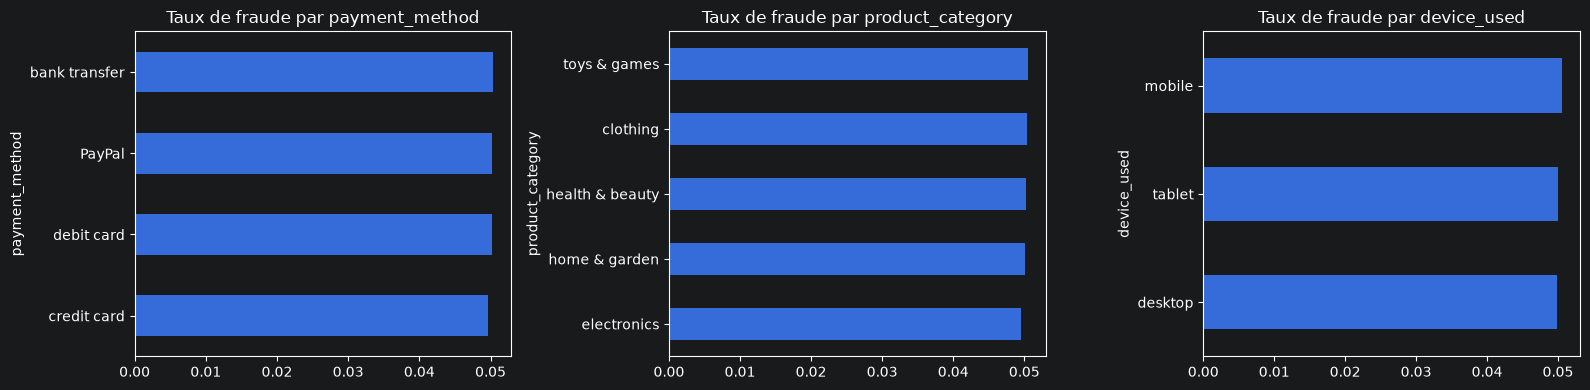

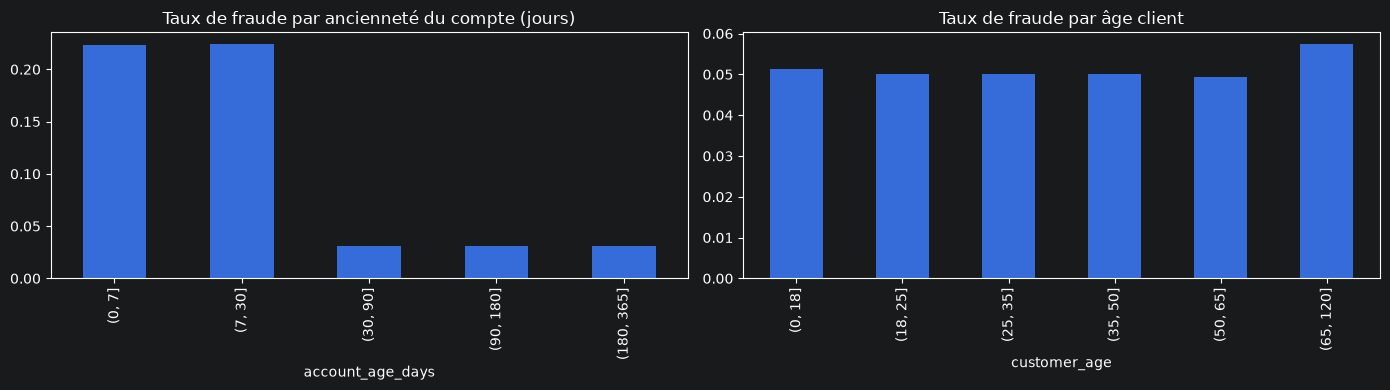

                mean     size
addr_match                   
0           0.049843   147523
1           0.050161  1325429


In [16]:
# Taux de fraude par catégorie / canal
cat_cols = ["payment_method", "product_category", "device_used"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cat_cols):
    df.groupby(c)[target].mean().sort_values().plot.barh(ax=ax)
    ax.set_title(f"Taux de fraude par {c}")
plt.tight_layout(); plt.show()

# Ancienneté du compte et âge (variables numériques clés)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby(pd.cut(df.account_age_days, [0,7,30,90,180,365,10_000]))[target].mean().plot.bar(ax=axes[0])
axes[0].set_title("Taux de fraude par ancienneté du compte (jours)")
df.groupby(pd.cut(df.customer_age, [0,18,25,35,50,65,120]))[target].mean().plot.bar(ax=axes[1])
axes[1].set_title("Taux de fraude par âge client")
plt.tight_layout(); plt.show()

# Variable adresses identiques ?
df["addr_match"] = (df.shipping_address == df.billing_address).astype(int)
print(df.groupby("addr_match")[target].agg(["mean", "size"]))

In [17]:
# Préparation

df = df.sort_values("transaction_date").reset_index(drop=True)

hour = df.transaction_date.dt.hour
df["hour_sin"] = np.sin(2*np.pi*hour/24)
df["hour_cos"] = np.cos(2*np.pi*hour/24)
df["dow"] = df.transaction_date.dt.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["is_night"] = hour.isin([0,1,2,3,4,5]).astype(int)
df["log_amount"] = np.log1p(df.transaction_amount)

C:\Users\Administrateur.Ghassen\AppData\Local\Temp\ipykernel_51124\1103765961.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df.transaction_date.dt.dayofweek


In [18]:
drop_cols = ["transaction_id", "customer_id", "ip_address", "shipping_address",
             "billing_address", "transaction_hour", "customer_location"]
cat_cols = ["payment_method", "product_category", "device_used"]

n = len(df)
i_tr, i_va = int(.6*n), int(.8*n)        # df déjà trié par date
split = np.array(["train"]*i_tr + ["val"]*(i_va-i_tr) + ["test"]*(n-i_va))

data = df.drop(columns=drop_cols).copy()
data = pd.get_dummies(data, columns=cat_cols, drop_first=False)   # n'utilise pas la cible

feature_cols = [c for c in data.columns
                if c not in [target, "transaction_date", "transaction_amount"]]
# transaction_amount est gardé à part pour le coût métier ; log_amount sert de variable

train, val, test = (data[split==s] for s in ["train", "val", "test"])
X_tr, y_tr = train[feature_cols], train[target]
X_va, y_va = val[feature_cols],   val[target]
X_te, y_te = test[feature_cols],  test[target]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(part):>8d} | {part.transaction_date.min().date()} → "
          f"{part.transaction_date.max().date()} | fraude {part[target].mean():.2%}")

train   883771 | 2024-01-01 → 2024-02-26 | fraude 5.02%
val     294590 | 2024-02-26 → 2024-03-15 | fraude 5.03%
test    294591 | 2024-03-15 → 2024-04-03 | fraude 4.99%


In [19]:
# déséquilibre

from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

def fit_eval(X, y, **kw):
    m = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1, **kw)
    m.fit(X, y)
    p = m.predict_proba(X_va)[:, 1]
    return average_precision_score(y_va, p), roc_auc_score(y_va, p)

spw = (y_tr==0).sum() / (y_tr==1).sum()
res = {}
res["Aucune"]            = fit_eval(X_tr, y_tr)
res["Poids de classe"]   = fit_eval(X_tr, y_tr, scale_pos_weight=spw)
Xu, yu = RandomUnderSampler(sampling_strategy=0.2, random_state=42).fit_resample(X_tr, y_tr)
res["Sous-échantillonnage 1:5"] = fit_eval(Xu, yu)
Xs, ys = SMOTE(sampling_strategy=0.2, random_state=42).fit_resample(X_tr, y_tr)
res["SMOTE 1:5"]         = fit_eval(Xs, ys)

print(pd.DataFrame(res, index=["PR-AUC val", "ROC-AUC val"]).T.round(4))

                          PR-AUC val  ROC-AUC val
Aucune                        0.3331       0.7688
Poids de classe               0.3337       0.7667
Sous-échantillonnage 1:5      0.3348       0.7685
SMOTE 1:5                     0.3352       0.7684


In [20]:
# Modélisation

# Imputation des âges aberrants (médiane calculée sur le TRAIN uniquement)
X_tr, X_va, X_te = X_tr.copy(), X_va.copy(), X_te.copy()
age_median = float(X_tr.loc[X_tr.customer_age > 0, "customer_age"].median())
for X in (X_tr, X_va, X_te):
    X.loc[X.customer_age <= 0, "customer_age"] = age_median
X_tr, X_va, X_te = (X.astype(float) for X in (X_tr, X_va, X_te))

# Cibles, montants et dates en numpy (pour le coût métier)
y_tr_, y_va_, y_te_ = y_tr.values, y_va.values, y_te.values
amt_va, amt_te = val.transaction_amount.values, test.transaction_amount.values
print(X_tr.shape, "| âge médian imputé :", age_median)

(883771, 22) | âge médian imputé : 35.0


In [21]:
# modèles supervisés

from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Stratégie anti-déséquilibre retenue (cf. comparaison en validation) : poids de classe
spw = (y_tr_ == 0).sum() / (y_tr_ == 1).sum()

# 1) Régression logistique pondérée (baseline interprétable)
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced", max_iter=500, C=1.0))
lr.fit(X_tr, y_tr_)

# 2) LightGBM, arrêt précoce sur la PR-AUC de validation
lgbm = LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                      min_child_samples=100, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, scale_pos_weight=spw,
                      metric="average_precision", random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_tr, y_tr_, eval_set=[(X_va, y_va_)],
         callbacks=[early_stopping(100, verbose=False), log_evaluation(0)])
print("LightGBM : meilleure itération =", lgbm.best_iteration_)

C:\Users\Administrateur.Ghassen\PycharmProjects\Fraud_project\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM : meilleure itération = 173


In [22]:
# non supervisées

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

scaler = StandardScaler().fit(X_tr)
Z_tr, Z_va, Z_te = (scaler.transform(X) for X in (X_tr, X_va, X_te))

# Isolation Forest sur tout le train
iso = IsolationForest(n_estimators=300, max_samples=256, random_state=42, n_jobs=-1).fit(Z_tr)

# LOF en mode « novelty » : trop coûteux sur 884 k lignes, on ajuste sur un sous-échantillon
rng = np.random.RandomState(42)
idx = rng.choice(len(Z_tr), 30_000, replace=False)
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1).fit(Z_tr[idx])

In [23]:
scores = {
    "Rég. logistique pondérée": (lr.predict_proba(X_va)[:,1],   lr.predict_proba(X_te)[:,1]),
    "LightGBM":                 (lgbm.predict_proba(X_va)[:,1], lgbm.predict_proba(X_te)[:,1]),
    "Isolation Forest":         (-iso.score_samples(Z_va),      -iso.score_samples(Z_te)),
    "LOF":                      (-lof.score_samples(Z_va),      -lof.score_samples(Z_te)),
}

In [24]:
# Évaluation

C_ALERT = 25.0              # coût d'analyse d'une alerte (hypothèse : ~20 min d'analyste + friction client)
CAPACITY_PER_DAY = 300      # dossiers qu'une équipe peut traiter par jour (hypothèse)

n_days = (val.transaction_date.max() - val.transaction_date.min()).days + 1
K_VA = CAPACITY_PER_DAY * n_days
K_TE = CAPACITY_PER_DAY * ((test.transaction_date.max() - test.transaction_date.min()).days + 1)
print(f"Budget d'alertes : k_val={K_VA}, k_test={K_TE} "
      f"(≈ {K_VA/len(y_va_):.1%} du volume ; la fraude représente {y_va_.mean():.1%})")

Budget d'alertes : k_val=5700, k_test=5700 (≈ 1.9% du volume ; la fraude représente 5.0%)


In [25]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, fbeta_score, matthews_corrcoef)

def topk(y, s, k):
    top = np.argsort(-s)[:k]
    tp = y[top].sum()
    return tp / k, tp / y.sum()                    # précision@k, rappel@k

def cost_curve(y, s, amt, c):
    """cost[j] = coût si on alerte les j transactions les mieux classées."""
    order = np.argsort(-s)
    fraud_amt = (amt * y)[order]
    caught = np.concatenate([[0.0], np.cumsum(fraud_amt)])
    return order, (fraud_amt.sum() - caught) + c * np.arange(len(s) + 1)

def pick_threshold(y, s, amt, c):
    order, cost = cost_curve(y, s, amt, c)
    j = int(cost.argmin())
    thr = np.inf if j == 0 else s[order][j - 1]    # on alerte si score >= thr
    return thr, j, cost[j]

def cost_at(y, s, amt, thr, c):
    alert = s >= thr
    return amt[(y == 1) & ~alert].sum() + c * alert.sum()

def baselines(y, amt, c):
    return {"aucun_modele": amt[y == 1].sum(), "tout_alerter": c * len(y)}

In [26]:
rows = []
for name, (s_va, s_te) in scores.items():
    thr, j, cost_va = pick_threshold(y_va_, s_va, amt_va, C_ALERT)
    p_va, r_va = topk(y_va_, s_va, K_VA)
    p_te, r_te = topk(y_te_, s_te, K_TE)
    rows.append({
        "Modèle": name,
        "PR-AUC val": average_precision_score(y_va_, s_va),
        "PR-AUC test": average_precision_score(y_te_, s_te),
        "ROC-AUC val": roc_auc_score(y_va_, s_va),
        "ROC-AUC test": roc_auc_score(y_te_, s_te),
        "Préc@k test": p_te, "Rappel@k test": r_te,
        "Coût test (seuil val)": cost_at(y_te_, s_te, amt_te, thr, C_ALERT),
    })
comp = pd.DataFrame(rows).set_index("Modèle")
base_te = baselines(y_te_, amt_te, C_ALERT)
comp["Gain vs aucun modèle"] = 1 - comp["Coût test (seuil val)"] / base_te["aucun_modele"]
print(f"Référence aléatoire : PR-AUC ≈ {y_te_.mean():.3f} | précision@k ≈ {y_te_.mean():.3f}")
print(f"Coût test sans modèle : {base_te['aucun_modele']:,.0f} | en alertant tout : {base_te['tout_alerter']:,.0f}")
comp.round(4)

Référence aléatoire : PR-AUC ≈ 0.050 | précision@k ≈ 0.050
Coût test sans modèle : 8,070,789 | en alertant tout : 7,364,775


,PR-AUC val,PR-AUC test,ROC-AUC val,ROC-AUC test,Préc@k test,Rappel@k test,Coût test (seuil val),Gain vs aucun modèle
Modèle,,,,,,,,
Rég. logistique pondérée,0.2479,0.2487,0.7189,0.7167,0.4419,0.1715,3292561.19,0.5920
LightGBM,0.3346,0.3310,0.7684,0.7642,0.5356,0.2079,2386332.06,0.7043
Isolation Forest,0.0646,0.0648,0.5824,0.5827,0.0842,0.0327,5709093.25,0.2926
LOF,0.0972,0.0981,0.6174,0.6185,0.2002,0.0777,4292318.09,0.4682


In [27]:
best = comp["PR-AUC val"].idxmax()
print("Modèle retenu :", best)

Modèle retenu : LightGBM


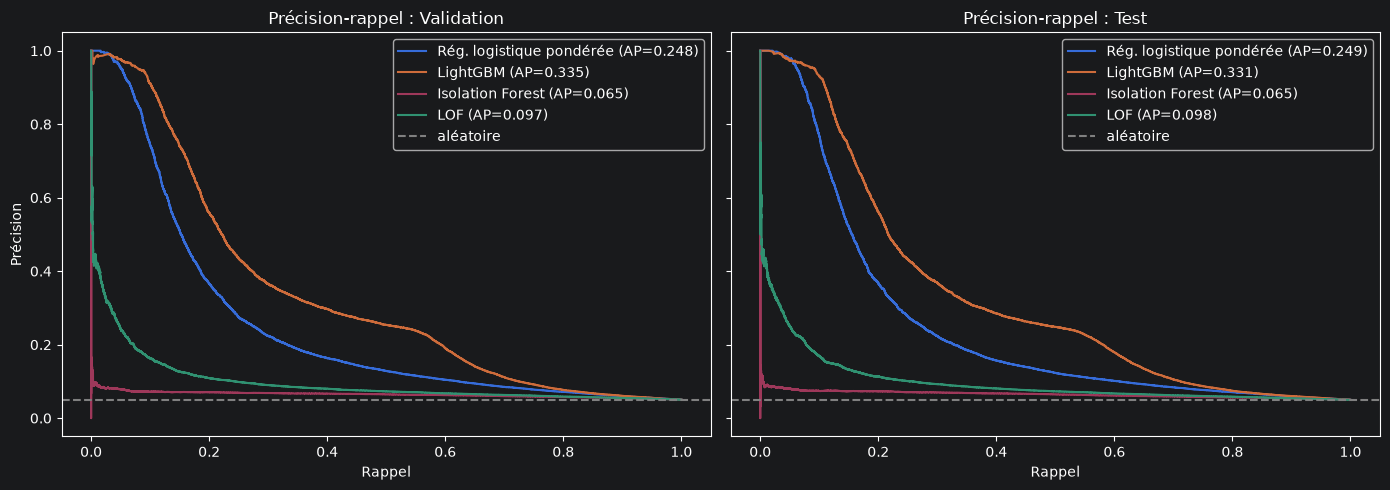

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (y, i, title) in zip(axes, [(y_va_, 0, "Validation"), (y_te_, 1, "Test")]):
    for name, sc in scores.items():
        p, r, _ = precision_recall_curve(y, sc[i])
        ax.plot(r, p, label=f"{name} (AP={average_precision_score(y, sc[i]):.3f})")
    ax.axhline(y.mean(), ls="--", c="gray", label="aléatoire")
    ax.set_xlabel("Rappel"); ax.set_title(f"Précision-rappel : {title}"); ax.legend()
axes[0].set_ylabel("Précision")
plt.tight_layout(); plt.show()

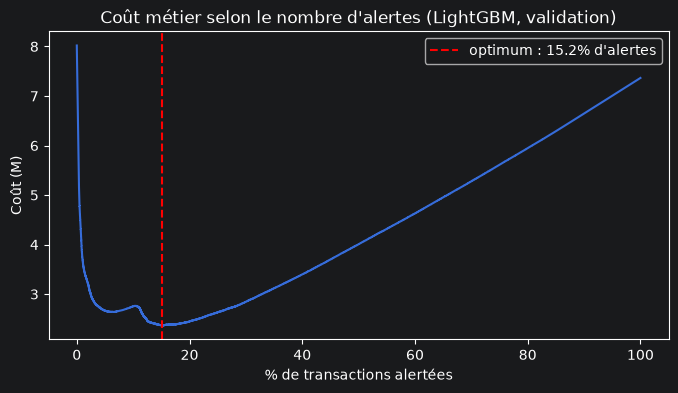

Seuil retenu = 0.4640


,Alertes,% alertées,Précision,Rappel,F2,MCC,Coût
Jeu,,,,,,,
val (seuil choisi ici),44772,0.1520,0.1973,0.5959,0.4244,0.2847,2366039.35
test (seuil confirmé),44800,0.1521,0.1923,0.5866,0.4160,0.2772,2386332.06


Coût test : seuil val = 2,386,332 | oracle test = 2,378,034 | sans modèle = 8,070,789


In [29]:
s_va, s_te = scores[best]
thr, j, cost_val = pick_threshold(y_va_, s_va, amt_va, C_ALERT)

# Courbe de coût en fonction du nombre d'alertes (validation)
_, cost_curve_va = cost_curve(y_va_, s_va, amt_va, C_ALERT)
plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(cost_curve_va)) / len(y_va_) * 100, cost_curve_va / 1e6)
plt.axvline(j / len(y_va_) * 100, c="r", ls="--", label=f"optimum : {j/len(y_va_):.1%} d'alertes")
plt.xlabel("% de transactions alertées"); plt.ylabel("Coût (M)"); plt.legend()
plt.title(f"Coût métier selon le nombre d'alertes ({best}, validation)"); plt.show()

def report(y, s, amt, thr, label):
    pred = (s >= thr).astype(int)
    return {"Jeu": label, "Alertes": int(pred.sum()), "% alertées": pred.mean(),
            "Précision": (y[pred == 1].mean() if pred.sum() else 0),
            "Rappel": y[pred == 1].sum() / y.sum(),
            "F2": fbeta_score(y, pred, beta=2), "MCC": matthews_corrcoef(y, pred),
            "Coût": cost_at(y, s, amt, thr, C_ALERT)}

final = pd.DataFrame([report(y_va_, s_va, amt_va, thr, "val (seuil choisi ici)"),
                      report(y_te_, s_te, amt_te, thr, "test (seuil confirmé)")]).set_index("Jeu")
print(f"Seuil retenu = {thr:.4f}")
display(final.round(4))

# Le seuil de la validation est-il proche du meilleur seuil possible sur le test ?
_, _, cost_oracle = pick_threshold(y_te_, s_te, amt_te, C_ALERT)
print(f"Coût test : seuil val = {final.loc['test (seuil confirmé)','Coût']:,.0f} | "
      f"oracle test = {cost_oracle:,.0f} | sans modèle = {base_te['aucun_modele']:,.0f}")

In [30]:
sens = []
for c in [5, 10, 25, 50, 100]:
    t, jj, _ = pick_threshold(y_va_, s_va, amt_va, c)
    rep = report(y_te_, s_te, amt_te, t, f"c={c}")
    rep["Coût"] = cost_at(y_te_, s_te, amt_te, t, c)
    rep["Sans modèle"] = baselines(y_te_, amt_te, c)["aucun_modele"]
    rep["Tout alerter"] = baselines(y_te_, amt_te, c)["tout_alerter"]
    sens.append(rep)
pd.DataFrame(sens).set_index("Jeu")[["% alertées","Précision","Rappel","F2","Coût","Sans modèle","Tout alerter"]].round(3)

,% alertées,Précision,Rappel,F2,Coût,Sans modèle,Tout alerter
Jeu,,,,,,,
c=5,0.417,0.089,0.743,0.301,1053069.86,8070789.43,1472955
c=10,0.280,0.120,0.673,0.349,1519958.79,8070789.43,2945910
c=25,0.152,0.192,0.587,0.416,2386332.06,8070789.43,7364775
c=50,0.044,0.354,0.311,0.319,2986392.41,8070789.43,14729550
c=100,0.028,0.437,0.246,0.270,3477456.59,8070789.43,29459100


C:\Users\Administrateur.Ghassen\PycharmProjects\Fraud_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Écart max SHAP vs natif LightGBM : 0.0


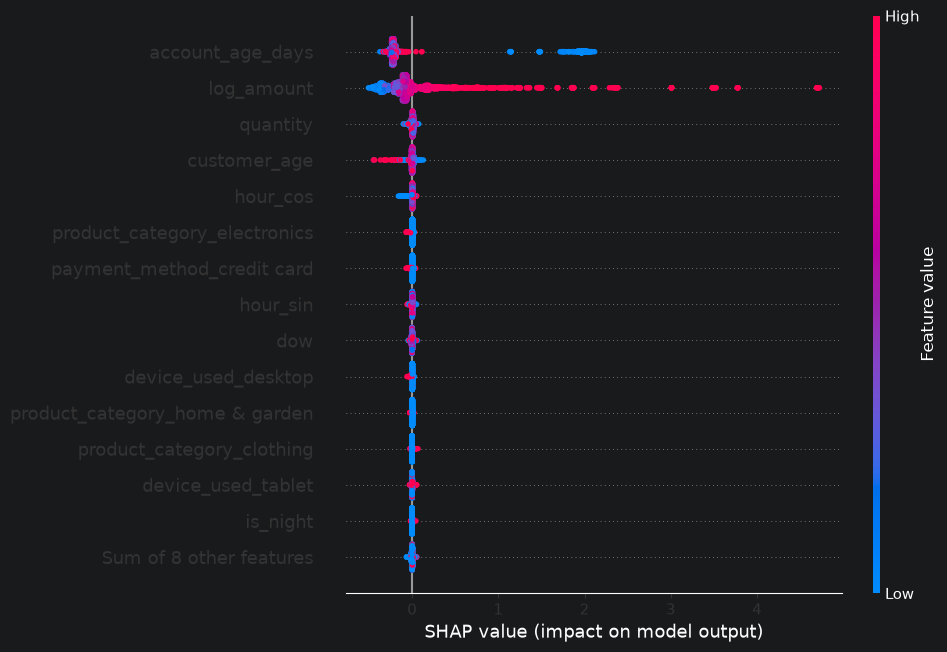

,feature,mean_abs_shap
0,account_age_days,0.397821
1,log_amount,0.244843
2,quantity,0.011480
3,customer_age,0.011282
4,hour_cos,0.008103
5,product_category_electronics,0.007398
6,payment_method_credit card,0.006417
7,hour_sin,0.005533
8,dow,0.005293
9,device_used_desktop,0.003577


In [31]:
# SHAP

import shap, io

sample = X_te.sample(5000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
sv = explainer(sample)
if sv.values.ndim == 3:            # selon la version de shap : (n, F, 2) -> classe « fraude »
    sv = sv[:, :, 1]

# Contrôle : SHAP == contributions natives LightGBM (utilisées ensuite dans l'API et l'app)
native = lgbm.predict(sample, pred_contrib=True)[:, :-1]
print("Écart max SHAP vs natif LightGBM :", np.abs(sv.values - native).max())

# Explication globale : beeswarm + importance moyenne
shap.plots.beeswarm(sv, max_display=15, show=False)
buf = io.BytesIO()
plt.gcf().savefig(buf, format="png", dpi=130, bbox_inches="tight")
beeswarm_png = buf.getvalue()                      # conservé pour l'application
plt.show()

shap_importance = (pd.DataFrame({"feature": sample.columns,
                                 "mean_abs_shap": np.abs(sv.values).mean(axis=0)})
                   .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
shap_importance.head(10)

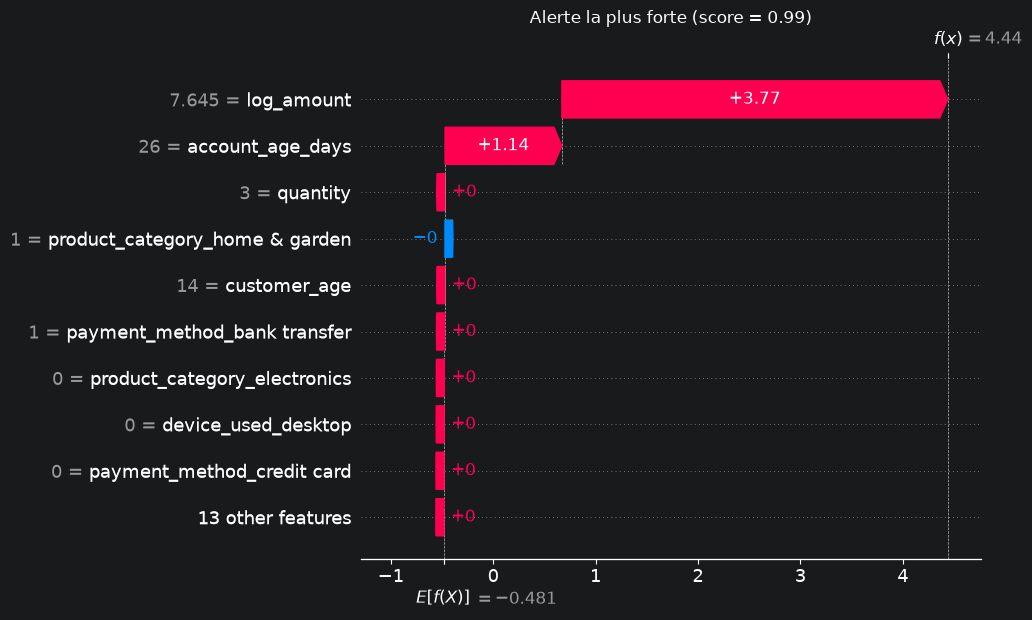

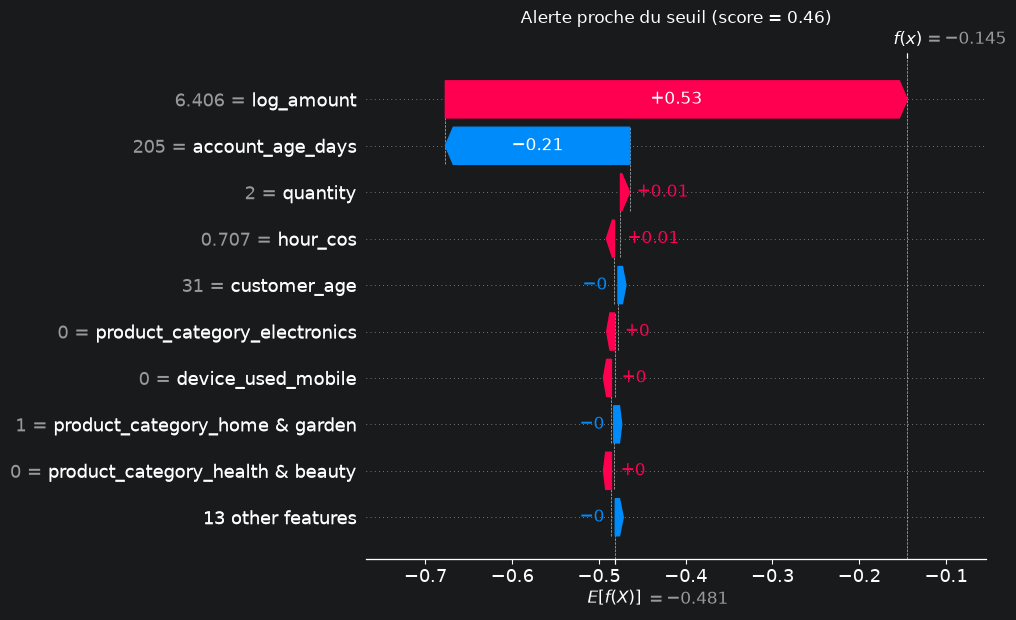

Codes motifs, alerte la plus forte :
log_amount = 7.6448  (+3.77)
account_age_days = 26  (+1.14)
quantity = 3  (+0.00)
customer_age = 14  (+0.00)

Codes motifs, alerte proche du seuil :
log_amount = 6.40632  (+0.53)
quantity = 2  (+0.01)
hour_cos = 0.707107  (+0.01)
product_category_electronics = 0  (+0.00)


In [32]:
# waterfall

p_s = lgbm.predict_proba(sample)[:, 1]
i_top = int(np.argmax(p_s))                         # alerte la plus forte
i_mid = int(np.argmin(np.abs(p_s - thr)))           # alerte « limite » (proche du seuil)

for i, titre in [(i_top, "Alerte la plus forte"), (i_mid, "Alerte proche du seuil")]:
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{titre} (score = {p_s[i]:.2f})"); plt.show()

def reason_codes(i, n=4):
    """Les n variables qui poussent le plus vers l'alerte."""
    s = pd.Series(sv.values[i], index=sample.columns)
    top = s[s > 0].nlargest(n)
    return [f"{f} = {sample.iloc[i][f]:g}  (+{v:.2f})" for f, v in top.items()]

print("Codes motifs, alerte la plus forte :"); print(*reason_codes(i_top), sep="\n")
print("\nCodes motifs, alerte proche du seuil :"); print(*reason_codes(i_mid), sep="\n")

In [33]:
d = df
hour_all = d.transaction_date.dt.hour.rename("hour")
raw_cats = ["payment_method", "product_category", "device_used"]
amt_log = np.log1p(d.transaction_amount)
bins = np.linspace(amt_log.min(), amt_log.max(), 61)

eda = {
    "kpi": {"n": int(len(d)), "fraud_rate": float(d[target].mean()),
            "start": d.transaction_date.min(), "end": d.transaction_date.max(),
            "mean_amount_fraud": float(d.loc[d[target] == 1, "transaction_amount"].mean()),
            "mean_amount_legit": float(d.loc[d[target] == 0, "transaction_amount"].mean())},
    "weekly": (d.set_index("transaction_date")[target].resample("W")
                 .agg(rate="mean", n="size").reset_index()),
    "hourly": d.groupby(hour_all)[target].agg(rate="mean", n="size").reset_index(),
    "by_cat": {c: d.groupby(c)[target].agg(rate="mean", n="size").reset_index() for c in raw_cats},
    "account_age": (d.groupby(pd.cut(d.account_age_days, [-1, 7, 30, 90, 180, 365, 10_000],
                                     labels=["≤ 7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "> 1 an"]),
                              observed=True)[target].agg(rate="mean", n="size").reset_index()),
    "amount_hist": pd.DataFrame({
        "amount": np.expm1((bins[:-1] + bins[1:]) / 2),
        "Légitime": np.histogram(amt_log[d[target] == 0], bins=bins, density=True)[0],
        "Fraude":   np.histogram(amt_log[d[target] == 1], bins=bins, density=True)[0]}),
}
eda["account_age"].columns = ["bucket", "rate", "n"]
print({k: (v.shape if hasattr(v, "shape") else "ok") for k, v in eda.items()})

{'kpi': 'ok', 'weekly': (14, 3), 'hourly': (24, 3), 'by_cat': 'ok', 'account_age': (5, 3), 'amount_hist': (60, 3)}


In [35]:
# export

import joblib, lightgbm, sklearn, os

# Courbes précision-rappel (test) de toutes les méthodes, allégées
pr_curves = {}
for name, (_, st_) in scores.items():
    p, r, _ = precision_recall_curve(y_te_, st_)
    idx = np.unique(np.linspace(0, len(p) - 1, 400).astype(int))
    pr_curves[name] = pd.DataFrame({"recall": r[idx], "precision": p[idx]})

# Transactions de la période de test (champs bruts) : « journées de démonstration » de l'app
demo_cols = ["transaction_id", "transaction_date", "transaction_amount", "payment_method",
             "product_category", "device_used", "quantity", "customer_age",
             "account_age_days", "addr_match"]
demo = df.iloc[i_va:][demo_cols].reset_index(drop=True)
assert len(demo) == len(X_te)

# Échantillon de parité : l'app doit reproduire exactement ces variables et ces scores
pos = np.random.RandomState(0).choice(len(X_te), 500, replace=False)
parity = {"raw": demo.iloc[pos].reset_index(drop=True),
          "X": X_te.iloc[pos].reset_index(drop=True),
          "score": lgbm.predict_proba(X_te.iloc[pos])[:, 1]}

artifacts = {
    "feature_cols": feature_cols,
    "cat_levels": {c: sorted(df[c].unique().tolist()) for c in raw_cats},
    "age_median": age_median,
    "model_name": best,
    "model": lgbm,
    "threshold": float(thr), "c_alert": C_ALERT, "capacity_per_day": CAPACITY_PER_DAY,
    "comparison": comp, "pr_curves": pr_curves,
    "val":  pd.DataFrame({"score": s_va.astype("float32"), "y": y_va_.astype("int8"), "amount": amt_va.astype("float32")}),
    "test": pd.DataFrame({"score": s_te.astype("float32"), "y": y_te_.astype("int8"), "amount": amt_te.astype("float32")}),
    "test_days": int((test.transaction_date.max() - test.transaction_date.min()).days + 1),
    "demo": demo, "parity": parity, "eda": eda,
    "shap_values_sample": pd.DataFrame(sv.values.astype("float32"), columns=sample.columns),
    "shap_importance": shap_importance, "shap_beeswarm_png": beeswarm_png,
    "versions": {"lightgbm": lightgbm.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
assert best == "LightGBM", "le modèle exporté est lgbm : adapter si un autre modèle est retenu"
joblib.dump(artifacts, "artifacts.joblib", compress=3)
print(f"artifacts.joblib : {os.path.getsize('artifacts.joblib')/1e6:.1f} Mo")
print("\nVersions à reproduire en local et au déploiement :")
print("pip install " + " ".join(f"{p}=={v}" for p, v in [("pandas", pd.__version__), ("numpy", np.__version__),
      ("scikit-learn", sklearn.__version__), ("lightgbm", lightgbm.__version__), ("joblib", joblib.__version__)]))

artifacts.joblib : 16.2 Mo

Versions à reproduire en local et au déploiement :
pip install pandas==3.1.0 numpy==2.5.4 scikit-learn==1.9.1 lightgbm==4.7.0 joblib==1.6.0
